# Research Question 2 - Dat A Project -  EDA and Methodology - DAT490 - Capstone

> **RQ2 - From Project Plan** - How did adverse event reporting patterns for ADHD medications change following
> the October 2022 Adderall shortage announcement and the May 2023 FDA stimulant
> labeling requirements, particularly regarding medication ineffectiveness, withdrawal,
> misuse, abuse, and addiction?

This notebook explores research question 2, one variable at a time, and with the proposed methodology. I am starting with our **`faers_adhd_study`**, the ADHD-only extracted data on MotherDuck.

---

## ADHD study data: overview

`faers_adhd_study` holds only the ADHD study group: 94,803 FAERS cases (Q4 2012 to Q2
2026) in which a stimulant or nonstimulant ADHD medicine is a suspect drug.

| Table | One row per |
|---|---|
| `adhd_cases` | case: class, dates, age, sex, reporter, every event flag, serious outcomes |
| `adhd_drug`, `adhd_reac`, `adhd_outc`, ... | drug, reaction term, outcome code, ... (not needed for RQ2) |

Research Question 2 only leverages `adhd_cases` which is already joined with the event flags. The event flags were setup as part of the data cleansing and alignment. The flags, for example `misuse_narrow`, were identified from our team's reviewed term list as identified in the project plan.

---

## RQ2 EDA summary

Predictors from `adhd_cases` were inspected for absent values, data quality, and how frequent stimulant reports in the window (January 2018 – February 2026, 49,965 cases) list an event related to research question 2.

| Variable | Missing / unknown | Insight | Scope Decision |
|---|---|---|---|
| `init_month` (date FDA first received the case) | 0% | Monthly stimulant cases range from 280 to 1,185; volume swings, so counts cannot be compared month to month | In Scope, timeline; review % of cases |
| `rq1_group` (drug classification) | 0% | 49,965 stimulant, 4,736 nonstimulant and 648 both-class cases in the window; 34.7% vs 14.8% list a qualified event | In Scope, Stimulant = main series, nonstimulant = comparison, both-class dropped |
| RQ2 event flags | 0% (yes/no) | Ineffectiveness 27.3% of stimulant cases; abuse 4.8%; misuse 1.9%; withdrawal 1.6%; addiction 0.4% (203 cases) | Keep all five; addiction and withdrawal are low quantities |
| `product_quality_supply_narrow` | 0% | 18.7% of stimulant cases; nearly half of these (45.9%) also report ineffectiveness | In Scope - control |
| `occp_cod` (reporter type) | 6.7% blank | Consumers file 54% of stimulant cases and list a qualified event far more often (41.1% vs 26.3% for physicians) | Detail, but out of scope for analysis |
| `rq1_group_confirmed` | 59.3% blank for stimulant cases | Only 40.7% of stimulant cases state ADHD on the drug row | Gut check only |
| `age_years`, `sex_category` | 53.5%, 26.1% | Not RQ2 variables; too often missing to split the monthly series | Not used |

---

## 0. Setup and connect to MotherDuck

In [ ]:
# @title Update duckDB Drivers (if needed)
!pip install --force-reinstall duckdb==1.5.6

In [ ]:
# @title Setup Code
import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf

# Add Motherduck TOKEN with " "
MOTHERDUCK_TOKEN =
con = duckdb.connect("md:faers_adhd_study", config={"motherduck_token": MOTHERDUCK_TOKEN})
RQ2_GROUPS = ("ineffectiveness", "withdrawal", "misuse", "abuse", "addiction")

RQ2 = list(RQ2_GROUPS)
START, END = "2018-01", "2026-02"
EVENTS = {"shortage": "2022-10-01", "label change": "2023-05-01"}
COLORS = {"STIMULANT": "#2a78d6", "NONSTIMULANT": "#eb6834"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 90})


def rq2_rate(frame, by, outcome="any_rq2"):
    """Cases, cases with the outcome, and the % with it, for each value of `by`."""
    out = frame.groupby(by, dropna=False, observed=True)[outcome].agg(
        cases="size", with_event="sum"
    )
    out["percent"] = (100 * out["with_event"] / out["cases"]).round(1)
    return out


def draw_event_lines(ax):
    for when in EVENTS.values():
        ax.axvline(pd.Timestamp(when), color="grey", ls="--", lw=1)

---

## 1. Load the cases for Research Question 2
We load one row per case, with only the columns this question uses. "Any RQ2 event" means the report lists at least one term from the five RQ2 groups. This gives us 94,803 distinct cases to review.

In [ ]:
# @title Case Loading
flags = [f"{g}_{t}" for g in (*RQ2, "product_quality_supply") for t in ("narrow", "broad")]
cases = con.sql(f"""
    SELECT caseid, rq1_group, rq1_group_confirmed, init_month, occp_cod, age_years,
           sex_category, {", ".join(flags)}
    FROM adhd_cases
""").df()
cases["month"] = pd.to_datetime(cases["init_month"]).dt.strftime("%Y-%m")
cases["any_rq2"] = cases[[f"{g}_narrow" for g in RQ2]].any(axis=1)
print(len(cases), "cases,", cases["caseid"].nunique(), "distinct")

94803 cases, 94803 distinct


---

## 2. Predictor Review
### 2.1 `init_month`: Confirm Timeline
Each case is dated by the month FDA **first** received it, so a follow-up report never moves a case later. Data was reviewed for missing dates, along with a review in volume.

In [ ]:
# @title Date Confirmation and totals per time period
print(cases["init_month"].isna().sum(), "cases with no date")
print(cases["month"].min(), "to", cases["month"].max())
by_year = (
    cases.groupby([pd.to_datetime(cases["init_month"]).dt.year, "rq1_group"])
    .size()
    .unstack(fill_value=0)
)
by_year.tail(10)

0 cases with no date
2004-10 to 2026-06


rq1_group,MULTI_ADHD_CLASS,NONSTIMULANT,STIMULANT
init_month,,,
2017,70,453,7562
2018,69,414,6787
2019,94,412,5311
2020,66,399,4933
2021,71,469,4909
2022,83,616,5997
2023,84,616,6947
2024,78,735,6903
2025,98,957,7111


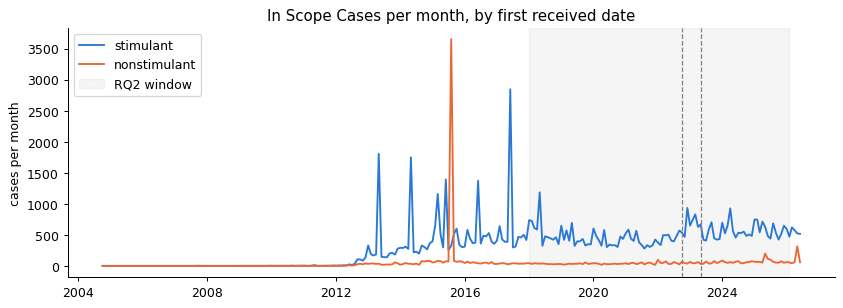

In [ ]:
# @title Cases Per Month - Graph
monthly_counts = cases.groupby(["month", "rq1_group"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.6))
for cls, color in COLORS.items():
    ax.plot(
        pd.to_datetime(monthly_counts.index), monthly_counts[cls], color=color, label=cls.lower()
    )
ax.axvspan(pd.Timestamp(START), pd.Timestamp(END), color="grey", alpha=0.08, label="RQ2 window")
draw_event_lines(ax)
ax.set_ylabel("cases per month")
ax.set_title("In Scope Cases per month, by first received date")
ax.legend()
plt.show()

#### `init_month`: Timeline Conclusion
No case is missing a date. Case volume changes frequently: the 2015 atomoxetine backlog, a dip around 2019–2021, and a rise from 2022. Inside the our research question window, the monthly stimulant cases range from 280 to 1,185. The months after February 2026 are still filling up and fall after FDA's move to its new reporting system (AEMS), so the window stops there.

**Overall decision: Aligned with project plan intent, `init_month` will establish the timeline, keep January 2018 – February 2026 as our study window, and compare the % of cases with an event rather than raw counts.**

### 2.2 `rq1_group`: medication class

In [ ]:
# @title Medication Class totals
window = cases[cases["month"].between(START, END)].copy()
rq2_rate(window, "rq1_group")

,cases,with_event,percent
rq1_group,,,
MULTI_ADHD_CLASS,648,266,41.0
NONSTIMULANT,4736,699,14.8
STIMULANT,49965,17342,34.7


#### `rq1_group` Predictor Conclusion:
No drug classification is missing. Within our window, stimulant cases outnumber nonstimulant cases about 10 to 1 (49,965 vs 4,736). About a third of stimulant cases (34.7%) list a qualified event. Non-stimulant cases containing only 14.8% with a qualified event. The 648 cases naming both drug classifications cannot be placed on one side, and should sit out.

**Overall Decision: Stimulant cases are the main series, with Non-stimulant cases being the comparison series. An Adderall shortage should not alter non-stimulant reports. Cases with both drug classification are excluded.**

### 2.3 Qualified Event Flags
Review the frequency of each event group, the shared frequency, the number of cases, and the impact of broad vs. narrow event flag consideration.

In [ ]:
# @title RQ2 Event Flags - Stimulants Only
stim = window[window["rq1_group"] == "STIMULANT"].copy()
event_table = pd.DataFrame(
    {
        "cases (narrow)": [int(stim[f"{g}_narrow"].sum()) for g in RQ2],
        "% narrow": [round(100 * stim[f"{g}_narrow"].mean(), 1) for g in RQ2],
        "% broad": [round(100 * stim[f"{g}_broad"].mean(), 1) for g in RQ2],
    },
    index=RQ2,
)
event_table

,cases (narrow),% narrow,% broad
ineffectiveness,13664,27.3,30.7
withdrawal,808,1.6,1.7
misuse,934,1.9,2.8
abuse,2378,4.8,4.8
addiction,203,0.4,0.8


In [ ]:
# @title Shared flag frequency (Does the flag occur with other flags by % of reports)
overlap = pd.DataFrame(
    {
        b: [round(100 * stim.loc[stim[f"{a}_narrow"], f"{b}_narrow"].mean(), 1) for a in RQ2]
        for b in RQ2
    },
    index=RQ2,
)
overlap

,ineffectiveness,withdrawal,misuse,abuse,addiction
ineffectiveness,100.0,1.3,0.5,0.3,0.0
withdrawal,22.3,100.0,6.2,11.0,2.1
misuse,6.7,5.4,100.0,23.2,1.1
abuse,1.9,3.7,9.1,100.0,0.8
addiction,0.5,8.4,4.9,9.9,100.0


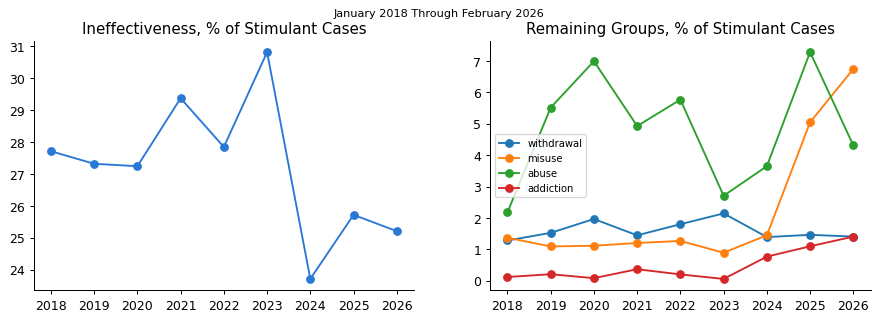

In [ ]:
# @title Flag frequency, % of total within year total
yearly = (
    stim.groupby(pd.to_datetime(stim["init_month"]).dt.year)[[f"{g}_narrow" for g in RQ2]].mean()
    * 100
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
yearly[["ineffectiveness_narrow"]].plot(
    ax=axes[0], marker="o", legend=False, color=COLORS["STIMULANT"]
)
axes[0].set_title("Ineffectiveness, % of Stimulant Cases")
yearly.drop(columns="ineffectiveness_narrow").plot(ax=axes[1], marker="o")
axes[1].set_title("Remaining Groups, % of Stimulant Cases")
fig.suptitle("January 2018 Through February 2026", fontsize=9)
axes[1].legend([g for g in RQ2 if g != "ineffectiveness"], fontsize=8)
for ax in axes:
    ax.set_xlabel("")
plt.show()

#### Event Flag Review Conclusion:
Ineffectiveness is by far the most common group (27.3% of stimulant cases), so it will drive the combined "any RQ2 event" series. The other four are rare: abuse 4.8%, misuse 1.9%, withdrawal 1.6% and addiction 0.4% (203 cases in eight years). The broad event list adds a few precentage points to ineffectiveness and misuse with little change to the others. Misuse and abuse often appear on the same report, however, each group should keep its own yes/no flag. By year, misuse increases in 2025 (roughly 5% of stimulant cases, up from about 1%), but it occurs within after the label change.

**Overall Decision: Keep all five event groups and test each one separately as well as combined. Noting that withdrawal and addiction having small quanities may lead to less signal value. The use of the broad event list as only as a sensitivity check.**

### 2.4 `product_quality_supply_narrow`: Control Flags

In [ ]:
# @title Do product quality or supply related flags correspond with RQ2 event flags?
rq2_rate(stim, "product_quality_supply_narrow", "ineffectiveness_narrow")

,cases,with_event,percent
product_quality_supply_narrow,,,
False,40625,9376,23.1
True,9340,4288,45.9


#### Control Flags Conclusion:
Product quality or supply terms, like "product substitution issue" appear in 18.7% of stimulant cases. Almost half of these reports (45.9%) also report ineffectiveness, compared with 23.1% of other reports, which aligns with complaints like "the new generic does not work".

**Overall Decision: Treat it as a control. If the shortage is documented within the reports, these flags should increase during the shortage.**

### 2.5 `occp_cod`: Report Source

In [ ]:
# @title Review of Report Source
stim["reporter"] = stim["occp_cod"].replace({"": None}).fillna("blank")
reporters = rq2_rate(stim, "reporter")
reporters["% of cases"] = (100 * reporters["cases"] / len(stim)).round(1)
reporters.sort_values("cases", ascending=False)

,cases,with_event,percent,% of cases
reporter,,,,
CN,26979,11090,41.1,54.0
MD,8170,2152,26.3,16.4
HP,7015,1722,24.5,14.0
blank,3347,1220,36.5,6.7
PH,2584,647,25.0,5.2
OT,1616,414,25.6,3.2
LW,254,97,38.2,0.5


In [ ]:
# @title Report source by impact window
stim["period"] = pd.cut(
    pd.to_datetime(stim["init_month"]),
    [
        pd.Timestamp("2017-12-31"),
        pd.Timestamp("2022-09-30"),
        pd.Timestamp("2023-04-30"),
        pd.Timestamp("2026-02-28"),
    ],
    labels=["before shortage", "shortage to label change", "after label change"],
)
pd.crosstab(stim["period"], stim["reporter"], normalize="index").mul(100).round(1)

reporter,CN,HP,LW,MD,OT,PH,blank
period,,,,,,,
before shortage,55.6,10.4,0.5,17.4,6.2,6.1,3.8
shortage to label change,60.8,18.6,0.6,14.7,0.0,3.4,1.9
after label change,50.1,17.8,0.6,15.3,0.0,4.4,11.8


#### `occp_cod` Report Source Conclusion:
Consumers (`CN`) file about 54% of stimulant cases, and their reports list an qualified event more often (41.1%) than reports from physicians (`MD`, 26.3%) or other health professionals (`HP`, 24.5%). The consumer portion also moves between periods (about 56% before the shortage, 61% during it and 50% after the label change). This may indicate that of any change in the this focused data set may be caused by source who preformed the reporting, this could be considered "notoriety bias" as mentioned in the project plan .

**Overall Decision: Do not adjust for reporter source. Consider the source mix by period next to the results for visual only, no further analysis within our research question.**

### 2.6 `rq1_group_confirmed` Explicit ADHD Use, Age, and Sex reporting

In [ ]:
# @title Absence/Presence of demographics
pd.DataFrame(
    {
        "missing / not confirmed %": [
            round(100 * stim["rq1_group_confirmed"].isna().mean(), 1),
            round(100 * stim["age_years"].isna().mean(), 1),
            round(100 * (~stim["sex_category"].isin(["F", "M"])).mean(), 1),
        ]
    },
    index=["rq1_group_confirmed", "age_years", "sex_category"],
)

,missing / not confirmed %
rq1_group_confirmed,59.3
age_years,53.5
sex_category,26.1


#### Demographics Conclusion:
Only about 41% of stimulant cases also state ADHD as the reason on the drug row, so a "confirmed ADHD use" series would be smaller but stricter. Age is missing in about 54% of cases and sex in about 26%, too often to split the monthly series by age or sex.

**Overall Decision: Only use `rq1_group_confirmed` as a gut check, do not leverage age or sex for this question.**

### 2.7 Monthly series:
A time-series model requires additional review prior to execution. We needed to review if some calendar months are consistently higher in reporting, along with a review to see if neighbouring months maintain a similarity.

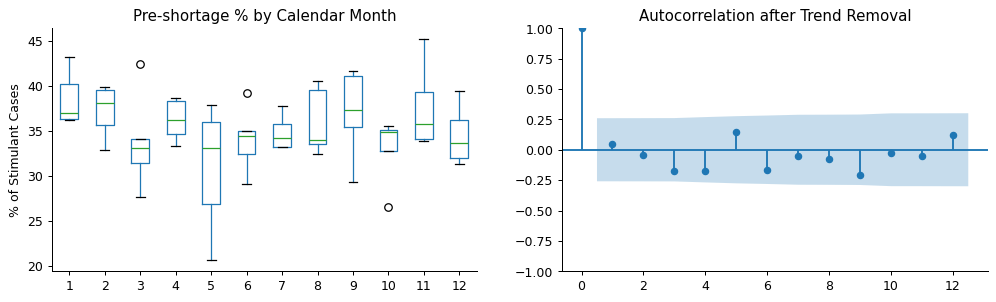

In [ ]:
# @title Comparison of combined months and correlation
pattern = (
    "(ineffectiveness|withdrawal|misuse|abuse|addiction|product_quality_supply)_(narrow|broad)"
)
any_of = lambda tier: " OR ".join(f"{g}_{tier}" for g in RQ2)  # noqa: E731
monthly = con.sql(f"""
    SELECT grouping, grp, strftime(init_month, '%Y-%m') AS month, count(*) AS cases,
           sum(COLUMNS('{pattern}')::INT),
           sum(({any_of("narrow")})::INT) AS any_narrow,
           sum(({any_of("broad")})::INT) AS any_broad
    FROM (UNPIVOT adhd_cases ON rq1_group, rq1_group_confirmed INTO NAME grouping VALUE grp)
    WHERE init_month IS NOT NULL
    GROUP BY ALL ORDER BY ALL
""").df()
main = monthly[(monthly["grouping"] == "rq1_group") & monthly["month"].between(START, END)]
pct = main.query("grp == 'STIMULANT'").assign(pct=lambda d: 100 * d["any_narrow"] / d["cases"])
before = pct[pct["month"] < "2022-10"].copy()
before["calendar month"] = before["month"].str[5:7].astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
before.boxplot(column="pct", by="calendar month", ax=axes[0], grid=False)
axes[0].set(title="Pre-shortage % by Calendar Month", xlabel="", ylabel="% of Stimulant Cases")
t = np.arange(len(before))
plot_acf(
    before["pct"].to_numpy() - np.polyval(np.polyfit(t, before["pct"], 1), t),
    lags=12,
    ax=axes[1],
    title="Autocorrelation after Trend Removal",
)
fig.suptitle("")
plt.show()

#### Monthly Series Conclusion:
The calendar months maintain similarity in the box plot, howeven the extent of overlap is greater in some more than others. This could be considered a step in October could partly show seasonality. Once the trend is removed, no autocorrelation bar falls outside the shaded band, so neighbouring months are only weakly similar.

**Overall Decision: Include calendar month terms in the model.**

---

## 3. Full Picture - All Qualified Events
One chart per event group, stimulant and nonstimulant together (rolling 3-month average of the % of each drug classification's cases listing the event). The dashed lines are the two announcements.

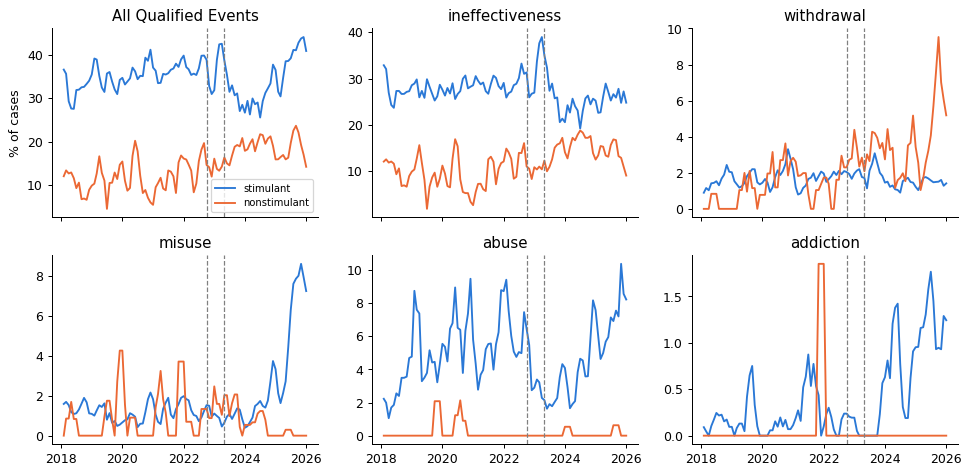

In [ ]:
# @title Big Picture - All Events rolling quarterly avg
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, g in zip(axes.flat, ["any", *RQ2]):
    for cls in COLORS:
        part = main[main["grp"] == cls]
        share = 100 * part[f"{g}_narrow"] / part["cases"]
        ax.plot(
            pd.to_datetime(part["month"]),
            share.rolling(3, center=True).mean(),
            color=COLORS[cls],
            label=cls.lower(),
        )
    draw_event_lines(ax)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_title("All Qualified Events" if g == "any" else g)
axes[0, 0].set_ylabel("% of cases")
axes[0, 0].legend(fontsize=8)
plt.show()

**General Summary**:
 Ineffectiveness is by far the largest group of cases, so it significantly aligns more to the "All Qualified Events" line: it climbs through the shortage and falls after the label change. Misuse and addiction are rare but turn upward after the label change, while withdrawal stays flat. The non-stimulant lines are lower and drift up after the label change.

---

## 4. Methodology
The EDA leads to these decisions, which align with the project plan:

| Decision | Rationale (from the EDA) |
|---|---|
| Outcome is the **% of stimulant cases** listing an event, by month | Monthly volume swings from 280 to 1,185 cases  |
| Window January 2018 – February 2026, dated by initial reporting | No missing dates  |
| Stimulant series, with nonstimulant as comparison and product quality/supply as control | Drug Classification mix and the control's link to ineffectiveness |
| Each group tested alone and combined | Groups differ in size and direction |
| Calendar-month terms | Seasonality and autocorrelation |


**Novel method: Project Plan alignment with three periods and a chi-square test.** We will compare the precentage of cases with each event before the shortage (Jan 2018 – Sep 2022), between the announcements (Nov 2022 – Apr 2023) and after the label change (Jun 2023 – Feb 2026). The two announcement months
are both before and after, so they are excluded.

**Advanced method: Project Plan alignment with segmented regression (interrupted time series).** A simple before and after comparison cannot tell a real change from a trend already underway. The segmented regression model will need to fit the monthly precentage with a time trend, a step and a slope change at each announcement, plus calendar-month terms.